In [1]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [25]:
def getEff(pythiaFile, pythiaCuts):
    df = applyCut(addNewBranches(getData(observables2+observabless2, pythiaFile, treeName[0])),pythiaCuts)
    match_miss, _ = np.histogram(df[ob], range=(range_low,range_high), bins=bins, weights=df['w'])
    match, _ = np.histogram(df[(df.ms>1) & (df.pts>15)][ob], range=(range_low,range_high), bins=bins, weights=df[(df.ms>1) & (df.pts>15)]['w'])
    return match/(1e-50+match_miss)

In [5]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [6]:
def addNewBranches(inputDataframe):
    df_temp = inputDataframe
    df_temp.eval('dm=m-mg',inplace=True)
    df_temp.eval('dm_frac=dm/m',inplace=True)
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp[df_temp.a<0.000001]['a'] = 0
    df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
    df_temp.mask(df_temp.isna(),-4.1,inplace=True)
    return df_temp

In [7]:
def calc_hist(vals, bins=10, weights=None, density=True):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [8]:
def getFull(effFile, pythiaCuts, ofCsvPath, ofCuts, it, nom=False, filelist=None):

    if filelist is None:
        filelist = np.arange(1,21)
        
    df2s = []
    for i in filelist:
        
        df_temp = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
        df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
        df_temp[df_temp.a<0.000001]['a'] = 0
        df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
        df_temp.mask(df_temp.isna(),-4.1,inplace=True)
        df_temp['weight'] = pd.read_csv(path+ofCsvPath+'it'+str(it)+'_seed'+str(i)+'.csv', low_memory=False)
        df2s.append(applyCut(df_temp, ofCuts))
    y2s = []
    for i in range(0, len(filelist)):
        y2s.append(np.histogram(df2s[i][ob], range=(range_low,range_high), bins=bins, weights=df2s[i]['weight'], density=True)[0])
    y2 = np.average(y2s, axis=0)
    y2_err = np.std(y2s, axis=0)
    
    y = y2/(1e-50+getEff(effFile, pythiaCuts))
    norm = sum(y)
    y = y/norm
    if (nom==False):
        err_seed=0
        err_it=0
    else:
        err_seed = y2_err/(np.sqrt(len(filelist))*norm) # use standard error

    return y/sum(y), err_seed/sum(y)

In [9]:
def getFullStat(effFile, pythiaCuts, ofCsvPath, ofCuts, it, nom=False, filelist=None):

    if filelist is None:
        filelist = np.arange(1,51)
        
    df2s = []
    for i in filelist:
        
        df_temp = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
        df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
        df_temp[df_temp.a<0.000001]['a'] = 0
        df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
        df_temp.mask(df_temp.isna(),-4.1,inplace=True)
        df_temp['weight'] = pd.read_csv(path+ofCsvPath+'it'+str(it)+'_statistic'+str(i)+'.csv', low_memory=False)
        df2s.append(applyCut(df_temp, ofCuts))
    y2s = []
    for i in range(0, len(filelist)):
        y2s.append(np.histogram(df2s[i][ob], range=(range_low,range_high), bins=bins, weights=df2s[i]['weight'], density=True)[0])
    y2 = np.average(y2s, axis=0)
    y2_err = np.std(y2s, axis=0)
    
    y = y2/(1e-50+getEff(effFile, pythiaCuts))
    norm = sum(y)
    y = y/norm
    if (nom==False):
        err_seed=0
        err_it=0
    else:
        err_seed = y2_err/(np.sqrt(len(filelist))*norm) # use standard error

    return y/sum(y), err_seed/sum(y)

In [11]:
path = '/gpfs/gibbs/project/caines/ys668/run12/csvs/'
nom_path = 'newemb_6d_largebatch_092723/'
hw_path = 'herwig_newemb_7dreweight_6dunfold_largebatch_092723/'
py8_path = 'pythia8_newemb_7dreweight_6dunfold_largebatch_092723/'
stat_path = 'newemb_6d_stat_largebatch_101923/'

In [17]:
it_mean = 15

20-30 GeV

In [12]:
cut='rg>0'
observables2 = ['pt','m','q2','rg','zg','mg','w','reject']
observabless2 = ['pts','ms','q2s','rgs','zgs','mgs','ws','rejects']
inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all0818_2.root']
treeName = ["MatchedTree"]
df_py6 = applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), cut+' and reject<=0 and rejects<=0 and w<5e-10')
df_py6 = addNewBranches(df_py6)

In [16]:
observables = ['q', 'qs', 'xsec','matching','pt','m','n','parton','mg','rg','zg','pts','ms','ns','partons','mgs','rgs','zgs', 'index','delta_r_1','delta_r_2','event_scale']
dataframes = []
files = ['/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_1208.txt']
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    df['w'] = np.ones(df.shape[0]) * (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    dataframes.append(df)
df = pd.concat([df for df in dataframes])
df = applyCut(df, cut)
df_hw = df[['pt','m','rg','zg','mg','w']]
df_hw = addNewBranches(df_hw)

In [15]:
observables = ['q05','q','q05s', 'qs', 'xsec','matching','pt','m','n','parton','mg','rg','zg','ng','pts','ms','ns','partons','mgs','rgs','zgs','ngs','index','delta_r_1','delta_r_2','event_scale']
dataframes = []
files = ['/vast/palmer/home.grace/ys668/output/run12/pythia1208_50pthat.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_45pthat50.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_40pthat45.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_35pthat40.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_30pthat35.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_25pthat30.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_20pthat25.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_15pthat20.txt']
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    df['w'] = np.ones(df.shape[0]) * (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    dataframes.append(df)
df = pd.concat([df for df in dataframes])
df = applyCut(df, cut)
df_py8 = df[['pt','m','rg','zg','mg','w']]
df_py8 = addNewBranches(df_py8)

In [18]:
cut = '20<pt<30 and a>0.0000001'
ob = 'loga'
range_low = -4.
range_high = -0.
bins = 16
binwidth = (range_high - range_low)/bins

In [19]:
bins_mc = 32
binwidth_mc = (range_high - range_low)/bins_mc

In [20]:
x = np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
x_mc = np.arange(range_low+(range_high-range_low)/(2*bins_mc),range_high+(range_high-range_low)/(2*bins_mc), (range_high-range_low)/bins_mc)

In [21]:
df_py6 = applyCut(df_py6, 'rg!=-1 and reject<=0 and rejects<=0 and '+cut)
y_nom_truth, err_nom_truth = calc_hist(df_py6[ob], bins=np.arange(range_low, range_high+binwidth_mc, binwidth_mc), weights=df_py6['w'], density=True)[:2]

In [22]:
df_hw = applyCut(df_hw, 'rg!=-1 and '+cut)
y_hw_truth, err_hw_truth = calc_hist(df_hw[ob], bins=np.arange(range_low, range_high+binwidth_mc, binwidth_mc), weights=df_hw['w'], density=True)[:2]

In [23]:
df_py8 = applyCut(df_py8, 'rg!=-1 and '+cut)
y_py8_truth, err_py8_truth = calc_hist(df_py8[ob], bins=np.arange(range_low, range_high+binwidth_mc, binwidth_mc), weights=df_py8['w'], density=True)[:2]

In [26]:
y_nom, err_seed = getFull('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)

In [27]:
y_hw, err_seed_hw = getFull('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)

In [28]:
y_p8, err_seed_p8 = getFull('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)

In [29]:
y_stat, err_stat = getFullStat('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    stat_path, cut, it_mean, nom=True)

In [31]:
rel_err1 = np.array([0,0,0, 0.01326951, 0.01107723, 0.00655016, 0.00229533, 0.00187876, 0.00145917, 0.00172876, 0.00391525, 0.00878632, 0.01316953,0,0,0])
rel_err2 = np.array([0,0,0, 0.0106145 , 0.01252629, 0.00582552, 0.00255784, 0.00257672, 0.00199461, 0.00248491, 0.00473744, 0.02353423, 0.00956913,0,0,0])
rel_err3 = np.array([0,0,0, 0.00766702, 0.01111538, 0.00519714, 0.00282691, 0.00205023, 0.00147707, 0.0025519 , 0.00524755, 0.00999809,0.01535578,0,0,0])

In [30]:
err4 = abs(np.array(y_nom/sum(y_nom))-np.array(y_hw/sum(y_hw)))
err5 = abs(np.array(y_nom/sum(y_nom))-np.array(y_p8/sum(y_p8)))
err6 = err_seed/sum(y_nom)
err_unf = []
for i in range(0,len(err4)):
    err_unf.append( np.sqrt( (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err_unf = np.array(err_unf)

In [32]:
rel_err_sys = np.sqrt(rel_err1**2 + rel_err2**2 + rel_err3**2 + (err_unf/y_nom)**2)

(0.0, 0.7)

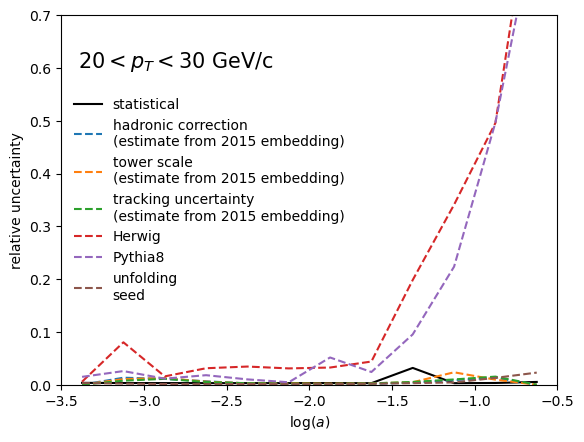

In [33]:
#plt.plot(x[2:-2], (rel_err_sys)[2:-2], color='indigo', label='all systematic')
plt.plot(x[2:-2], (err_stat/y_nom)[2:-2], color='k', label='statistical')
plt.plot(x[2:-2], rel_err1[2:-2], '--', label='hadronic correction\n(estimate from 2015 embedding)')
plt.plot(x[2:-2], rel_err2[2:-2], '--', label='tower scale\n(estimate from 2015 embedding)')
plt.plot(x[2:-2], rel_err3[2:-2], '--', label='tracking uncertainty\n(estimate from 2015 embedding)')
plt.plot(x[2:-2], (err4/y_nom)[2:-2], '--', label='Herwig')
plt.plot(x[2:-2], (err5/y_nom)[2:-2], '--', label='Pythia8')
plt.plot(x[2:-2], (err6/y_nom)[2:-2], '--', label='unfolding\nseed')
plt.ylabel('relative uncertainty')
plt.xlabel('$\log(a)$')
plt.legend(frameon=False, fontsize=10, loc='center left')
plt.text(-3.4,0.6,'$20<p_T<30$ GeV/c', fontsize=15)
plt.xlim(left=-3.5, right=-0.5)
plt.ylim(0,0.7)

In [34]:
x_theory = np.arange(-4,0.,0.1)
y_theory_high = np.array([0.00230224,0.00328527,0.00471761,0.00679335,0.00978628,0.0141022,0.0203903,0.0297669,0.0442317,\
                        0.0673853,0.105525,0.168922,0.272275,0.432534,0.663767,0.971291,1.33146,1.62808,1.64876,1.32896,\
                        0.861695,0.383962,0.,0.,0.,0.,0.,0.,0.,0.,0.,0.,0.,0.,0,0.,0.,0.,0.,0.])
y_theory_low = np.array([0.00140285,0.00184613,0.00245432,0.00329726,0.00447562,0.006135,0.00848906,0.0118608,0.0167596,\
                         0.0240261,0.0350916,0.0524148,0.080125,0.124743,0.195424,0.302698,0.455293,0.656572,0.897833,1.13247,\
                         1.24607,1.12537,0.816257,0.497301,0.313225,0.255655,0.216545,0.18826,0.166828,0.15,0.136413,0.125195,\
                         0.115764,0.107713,0.100754,0.0946744,0.0893127,0.0845462,0.0802789,0.0764346]) 

In [35]:
y_theory = 0.5*(y_theory_low+y_theory_high)
yerr = abs(y_theory - y_theory_low)

(0.0, 1.7)

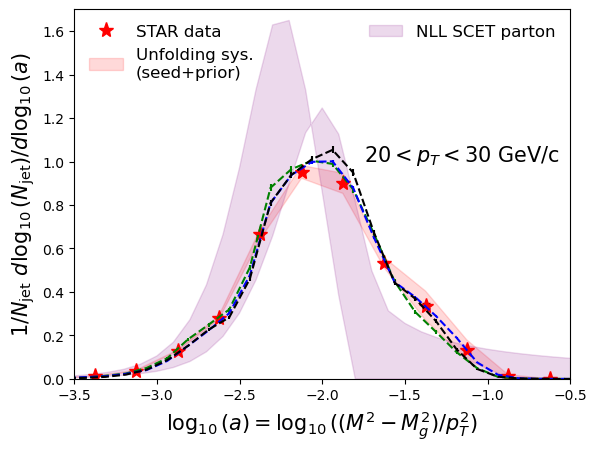

In [36]:
fig, ax = plt.subplots()
#plt.text(-3.4, 0.5,'Cuts on data and MC:\n$0<R_g<0.4$\nweak decays off\n$\pi^0$ decays on')
plt.errorbar(x, 4*y_nom/sum(y_nom), yerr=4*err_stat, capsize=3, color='darkred', markersize=11, ls='none')
line1, = plt.plot(x, 4*y_nom/sum(y_nom), label='STAR data', color='r', marker='*', markersize=11, ls='none')
line2 = plt.fill_between(x, 4*(y_nom/sum(y_nom)-err_unf), 4*(y_nom/sum(y_nom)+err_unf), color='r', alpha=0.15, label='Unfolding sys.\n(seed+prior)')
l1 = ax.legend(handles=[line1,line2], frameon=False, loc='upper left', fontsize=12)
ax.add_artist(l1)
#plt.text(-3.4, 1.0, '6D multifolded\n15 iterations\nFake rate from old emb.\nefficiency from new emb.')
line3 = plt.errorbar(x_mc, 8*y_hw_truth/sum(y_hw_truth), yerr=8*err_hw_truth/sum(y_hw_truth), label='HERWIG', color='g', linestyle='--')
line4 = plt.errorbar(x_mc, 8*y_nom_truth/sum(y_nom_truth), yerr=8*err_nom_truth/sum(y_nom_truth), label='PYTHIA6', color='b', linestyle='--')
line5 = plt.errorbar(x_mc, 8*y_py8_truth/sum(y_py8_truth), yerr=8*err_py8_truth/sum(y_py8_truth), label='PYTHIA8', color='k', linestyle='--')
line6 = plt.fill_between(x_theory, y_theory_high, y_theory_low, label='NLL SCET parton', color='purple', alpha=0.15)
ax.legend(handles=[line6], frameon=False, loc='upper right', fontsize=12)
plt.text(-1.75, 1,'$20<p_T<30$ GeV/c', fontsize=15)
plt.xlabel('$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$', fontsize=15)
plt.ylabel(r'$1/N_{\mathrm{jet}}$ $d\log_{10}(N_{\mathrm{jet}})/d\log_{10}(a)$', fontsize=15)
plt.xlim(-3.5,-0.5)
plt.ylim(0,1.7)

30-50 GeV

In [40]:
cut='rg>0'
observables2 = ['pt','m','q2','rg','zg','mg','w','reject']
observabless2 = ['pts','ms','q2s','rgs','zgs','mgs','ws','rejects']
inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all0818_2.root']
treeName = ["MatchedTree"]
df_py6 = applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), cut+' and reject<=0 and rejects<=0 and w<5e-10')
df_py6 = addNewBranches(df_py6)

In [41]:
observables = ['q', 'qs', 'xsec','matching','pt','m','n','parton','mg','rg','zg','pts','ms','ns','partons','mgs','rgs','zgs', 'index','delta_r_1','delta_r_2','event_scale']
dataframes = []
files = ['/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_1208.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_1208.txt']
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    df['w'] = np.ones(df.shape[0]) * (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    dataframes.append(df)
df = pd.concat([df for df in dataframes])
df = applyCut(df, cut)
df_hw = df[['pt','m','rg','zg','mg','w']]
df_hw = addNewBranches(df_hw)

In [42]:
observables = ['q05','q','q05s', 'qs', 'xsec','matching','pt','m','n','parton','mg','rg','zg','ng','pts','ms','ns','partons','mgs','rgs','zgs','ngs','index','delta_r_1','delta_r_2','event_scale']
dataframes = []
files = ['/vast/palmer/home.grace/ys668/output/run12/pythia1208_50pthat.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_45pthat50.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_40pthat45.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_35pthat40.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_30pthat35.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_25pthat30.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_20pthat25.txt', \
         '/vast/palmer/home.grace/ys668/output/run12/pythia1208_15pthat20.txt']
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    df['w'] = np.ones(df.shape[0]) * (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    dataframes.append(df)
df = pd.concat([df for df in dataframes])
df = applyCut(df, cut)
df_py8 = df[['pt','m','rg','zg','mg','w']]
df_py8 = addNewBranches(df_py8)

In [43]:
cut = '30<pt<50 and a>0.0000001'
ob = 'loga'
range_low = -4.
range_high = -0.
bins = 16
binwidth = (range_high - range_low)/bins

In [44]:
bins_mc = 32
binwidth_mc = (range_high - range_low)/bins_mc

In [45]:
x = np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
x_mc = np.arange(range_low+(range_high-range_low)/(2*bins_mc),range_high+(range_high-range_low)/(2*bins_mc), (range_high-range_low)/bins_mc)

In [46]:
df_py6 = applyCut(df_py6, 'rg!=-1 and reject<=0 and rejects<=0 and '+cut)
y_nom_truth, err_nom_truth = calc_hist(df_py6[ob], bins=np.arange(range_low, range_high+binwidth_mc, binwidth_mc), weights=df_py6['w'], density=True)[:2]

In [47]:
df_hw = applyCut(df_hw, 'rg!=-1 and '+cut)
y_hw_truth, err_hw_truth = calc_hist(df_hw[ob], bins=np.arange(range_low, range_high+binwidth_mc, binwidth_mc), weights=df_hw['w'], density=True)[:2]

In [48]:
df_py8 = applyCut(df_py8, 'rg!=-1 and '+cut)
y_py8_truth, err_py8_truth = calc_hist(df_py8[ob], bins=np.arange(range_low, range_high+binwidth_mc, binwidth_mc), weights=df_py8['w'], density=True)[:2]

In [49]:
y_nom, err_seed = getFull('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)

In [50]:
y_hw, err_seed_hw = getFull('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)

In [51]:
y_p8, err_seed_p8 = getFull('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)

In [52]:
y_stat, err_stat = getFullStat('/vast/palmer/home.grace/ys668/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    stat_path, cut, it_mean, nom=True)

In [53]:
err4 = abs(np.array(y_nom/sum(y_nom))-np.array(y_hw/sum(y_hw)))
err5 = abs(np.array(y_nom/sum(y_nom))-np.array(y_p8/sum(y_p8)))
err6 = err_seed/sum(y_nom)
err_unf = []
for i in range(0,len(err4)):
    err_unf.append( np.sqrt( (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
err_unf = np.array(err_unf)

(0.0, 0.7)

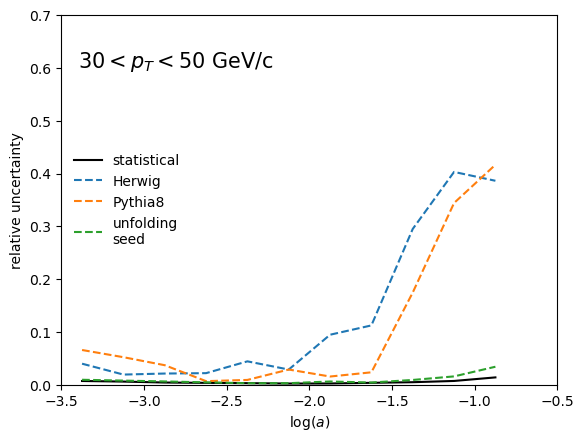

In [54]:
#plt.plot(x[2:-2], (rel_err_sys)[2:-2], color='indigo', label='all systematic')
plt.plot(x[2:-2], (err_stat/y_nom)[2:-2], color='k', label='statistical')
#plt.plot(x[2:-2], rel_err1[2:-2], '--', label='hadronic correction\n(estimate from 2015 embedding)')
#plt.plot(x[2:-2], rel_err2[2:-2], '--', label='tower scale\n(estimate from 2015 embedding)')
#plt.plot(x[2:-2], rel_err3[2:-2], '--', label='tracking uncertainty\n(estimate from 2015 embedding)')
plt.plot(x[2:-2], (err4/y_nom)[2:-2], '--', label='Herwig')
plt.plot(x[2:-2], (err5/y_nom)[2:-2], '--', label='Pythia8')
plt.plot(x[2:-2], (err6/y_nom)[2:-2], '--', label='unfolding\nseed')
plt.ylabel('relative uncertainty')
plt.xlabel('$\log(a)$')
plt.legend(frameon=False, fontsize=10, loc='center left')
plt.text(-3.4,0.6,'$30<p_T<50$ GeV/c', fontsize=15)
plt.xlim(left=-3.5, right=-0.5)
plt.ylim(0,0.7)

Text(0, 0.5, '$1/N_{\\mathrm{jet}}$ $d\\log_{10}(N_{\\mathrm{jet}})/d\\log_{10}(a)$')

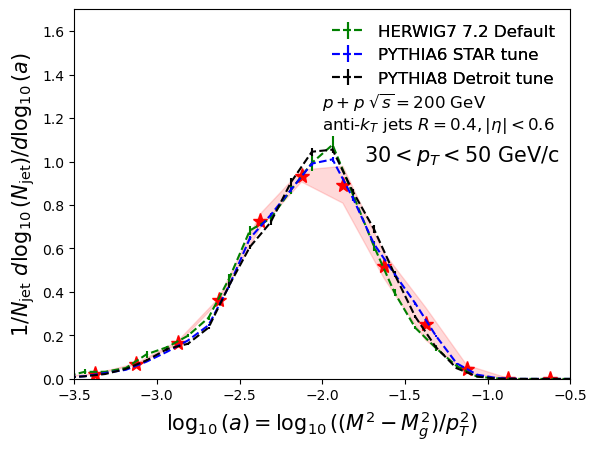

In [55]:
fig, ax = plt.subplots()
plt.text(-2, 1.15, '$p+p$ $\sqrt{s}=200$ GeV\nanti-$k_T$ jets $R=0.4, |\eta|<0.6$', fontsize=12)
plt.text(-1.75, 1,'$30<p_T<50$ GeV/c', fontsize=15)
line1, = plt.plot(x, 4*y_nom/sum(y_nom), label='STAR data', color='r', marker='*', markersize=11, ls='none')
line2 = plt.fill_between(x, 4*(y_nom/sum(y_nom)-err_unf), 4*(y_nom/sum(y_nom)+err_unf), color='r', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line3 = plt.errorbar(x_mc, 8*y_hw_truth/sum(y_hw_truth), yerr=8*err_hw_truth/sum(y_hw_truth), label='HERWIG7 7.2 Default', color='g', linestyle='--')
line4 = plt.errorbar(x_mc, 8*y_nom_truth/sum(y_nom_truth), yerr=8*err_nom_truth/sum(y_nom_truth), label='PYTHIA6 STAR tune', color='b', linestyle='--')
line5 = plt.errorbar(x_mc, 8*y_py8_truth/sum(y_py8_truth), yerr=8*err_py8_truth/sum(y_py8_truth), label='PYTHIA8 Detroit tune', color='k', linestyle='--')
l2 = ax.legend(handles=[line3, line4, line5], frameon=False, loc='upper right', fontsize=12)
ax.add_artist(l2)
plt.xlabel('log(a)')
plt.xlim(left=range_low, right=range_high)
plt.ylim(0,1.7)
plt.xlim(-3.5,-0.5)
plt.xlabel('$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$', fontsize=15)
plt.ylabel(r'$1/N_{\mathrm{jet}}$ $d\log_{10}(N_{\mathrm{jet}})/d\log_{10}(a)$', fontsize=15)